In [1]:
import pandas as pd
import numpy as np
import joblib

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

In [2]:
X_valid = pd.read_csv("../data/processed/X_valid.csv")

y_valid = pd.read_csv(
    "../data/processed/y_valid.csv"
).squeeze()

model_names = [
    "logistic_regression",
    "decision_tree",
    "random_forest",
    "xgboost"
]

loaded_models = {}

for name in model_names:

    loaded_models[name] = joblib.load(
        f"../models/{name}.joblib"
    )

In [3]:
evaluation_results = []

for name, model in loaded_models.items():

    y_pred = model.predict(X_valid)

    y_prob = model.predict_proba(X_valid)[:, 1]

    evaluation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_valid, y_pred),
        "Precision": precision_score(y_valid, y_pred),
        "Recall": recall_score(y_valid, y_pred),
        "F1": f1_score(y_valid, y_pred),
        "ROC_AUC": roc_auc_score(y_valid, y_prob),
        "PR_AUC": average_precision_score(y_valid, y_prob)
    })

evaluation_df = pd.DataFrame(evaluation_results)

evaluation_df.sort_values(
    by="PR_AUC",
    ascending=False
)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
0,logistic_regression,0.749468,0.517647,0.823529,0.635707,0.859394,0.678084
3,xgboost,0.762243,0.536449,0.767380,0.631463,0.848693,0.670740
2,random_forest,0.789922,0.596059,0.647059,0.620513,0.835720,0.620122
1,decision_tree,0.752307,0.523191,0.754011,0.617744,0.824917,0.605412


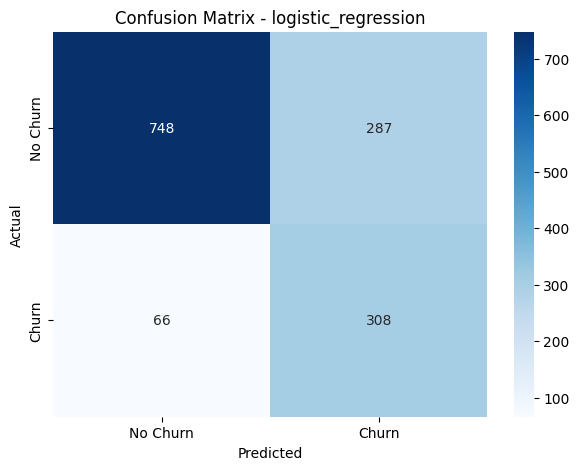

In [4]:
best_model_name = (
    evaluation_df
    .sort_values("PR_AUC", ascending=False)
    .iloc[0]["Model"]
)

best_model = loaded_models[best_model_name]

y_pred = best_model.predict(X_valid)

cm = confusion_matrix(y_valid, y_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion Matrix - {best_model_name}")

plt.show()

In [5]:
print(
    classification_report(
        y_valid,
        y_pred,
        target_names=["No Churn", "Churn"]
    )
)

              precision    recall  f1-score   support

    No Churn       0.92      0.72      0.81      1035
       Churn       0.52      0.82      0.64       374

    accuracy                           0.75      1409
   macro avg       0.72      0.77      0.72      1409
weighted avg       0.81      0.75      0.76      1409



<Figure size 800x600 with 0 Axes>

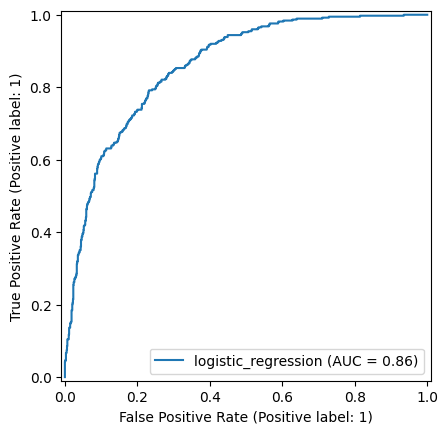

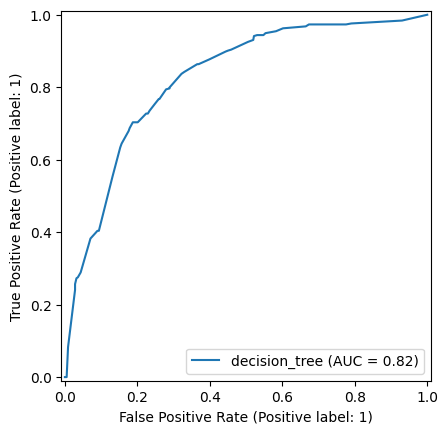

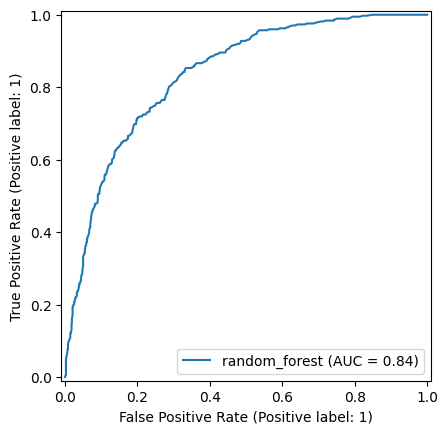

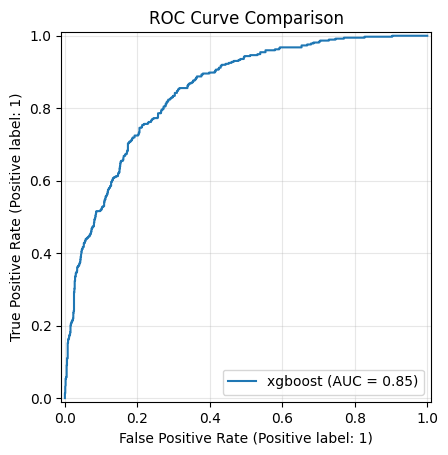

In [7]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay   # اگر import نشده باشد

plt.figure(figsize=(8, 6))

for name, model in loaded_models.items():
    RocCurveDisplay.from_estimator(
        model,
        X_valid,
        y_valid,          # ← اضافه شد
        name=name,
    )

plt.title("ROC Curve Comparison")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

<Figure size 800x600 with 0 Axes>

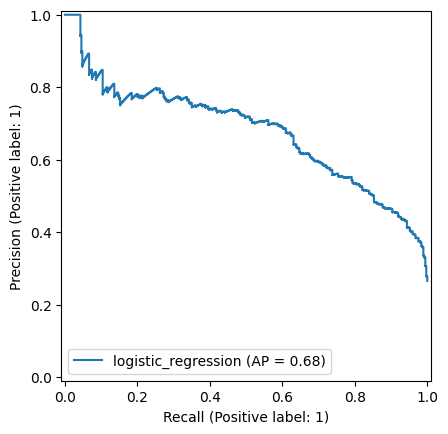

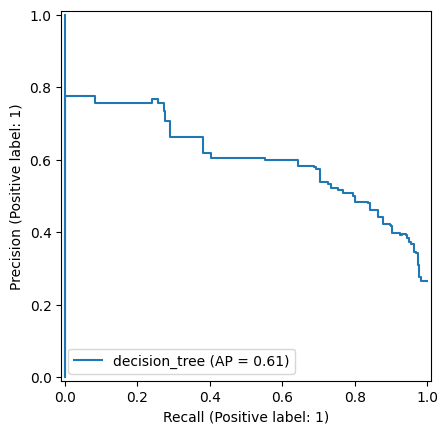

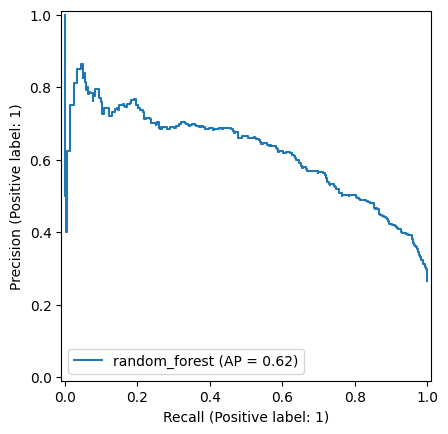

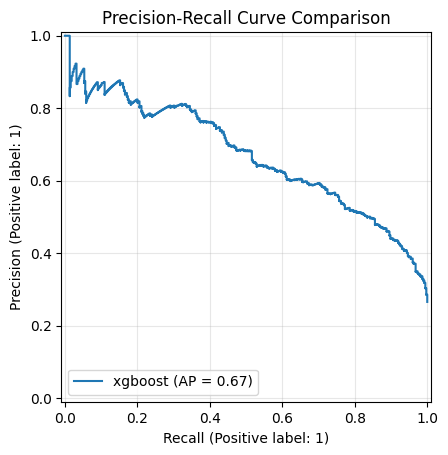

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import PrecisionRecallDisplay   # اگر import نشده

plt.figure(figsize=(8, 6))

for name, model in loaded_models.items():
    PrecisionRecallDisplay.from_estimator(
        model,
        X_valid,
        y_valid,          # ← این خط اضافه شد
        name=name,
    )

plt.title("Precision-Recall Curve Comparison")
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.show()